# TRAG demo
Podaci iz 2023. preuzeti s Registra onečišćavanja okoliša (ROO). Uspoređujemo sve lokacije s prijavljenom obradom **R3, 19 12 04 (plastika i guma)**. Uz notebook trebaju biti `obrada_2023.xlsx` i `nastanak_2023.xlsx`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

obrada = pd.read_excel("obrada_2023.xlsx", dtype={"OIB": str})
nastanak = pd.read_excel("nastanak_2023.xlsx", dtype={"OIB": str})

# Kratki nazivi da ostatak koda bude čitljiv.
nazivi = {
    "Godina": "godina",
    "OIB": "oib",
    "Naziv organizacijske jedinice na lokaciji": "pogon",
    "Ulica i kućni broj organizacijske jedinice": "adresa",
    "Grad/naselje organizacijske jedinice": "mjesto",
    "Ključni broj otpada": "otpad",
    "Postupanje s otpadom - postupak": "postupak",
    "Postupanje s otpadom - količina (t)": "obradeno",
    "Nastalo (t)": "nastalo",
}
obrada = obrada.rename(columns=nazivi)
nastanak = nastanak.rename(columns=nazivi)

kljuc = ["godina", "oib", "pogon", "adresa", "mjesto"]
for df in [obrada, nastanak]:
    for stupac in kljuc[1:]:
        df[stupac] = df[stupac].astype("string").str.strip()

In [2]:
r3 = obrada[(obrada["godina"] == 2023) & (obrada["postupak"] == "R3")]
plastika = r3[r3["otpad"] == "19 12 04"]

usporedba = plastika.groupby(kljuc, dropna=False)["obradeno"].sum(min_count=1)
usporedba = usporedba.reset_index(name="plastika_t")

ukupno_r3 = r3.groupby(kljuc, dropna=False)["obradeno"].sum(min_count=1)
ukupno_r3 = ukupno_r3.reset_index(name="r3_t")

ukupno_nastalo = nastanak.groupby(kljuc, dropna=False)["nastalo"].sum(min_count=1)
ukupno_nastalo = ukupno_nastalo.reset_index(name="nastalo_t")

usporedba = usporedba.merge(ukupno_r3, on=kljuc, validate="one_to_one")
usporedba = usporedba.merge(ukupno_nastalo, on=kljuc, how="left", validate="one_to_one")

if usporedba["nastalo_t"].isna().any() or (usporedba["r3_t"] <= 0).any():
    raise ValueError("Nedostaje nastanak otpada ili je R3 jednak nuli; provjeri zapise.")

usporedba["omjer_pct"] = 100 * usporedba["nastalo_t"] / usporedba["r3_t"]
usporedba = usporedba.sort_values("omjer_pct").reset_index(drop=True)

# Ovdje nema imena pogona ni ručno zadanog 'sumnjivog' slučaja.
najmanji = usporedba.loc[usporedba["omjer_pct"].idxmin()]
najveci = usporedba.loc[usporedba["plastika_t"].idxmax()]

In [3]:
print(f"Uspoređeno lokacija: {len(usporedba)}")
print(f"Najmanji omjer: {najmanji['pogon']} — {najmanji['mjesto']}")
print(f"Najveća količina 19 12 04 pod R3: {najveci['pogon']} — {najveci['mjesto']}")

tablica = usporedba[["pogon", "mjesto", "plastika_t", "r3_t", "nastalo_t", "omjer_pct"]].head(3)
tablica = tablica.rename(columns={
    "pogon": "Pogon", "mjesto": "Mjesto", "plastika_t": "R3, 19 12 04 (t)",
    "r3_t": "Ukupno R3 (t)", "nastalo_t": "Nastalo na lokaciji (t)",
    "omjer_pct": "Nastalo / ukupno R3 (%)",
})
display(tablica.round(3))

Uspoređeno lokacija: 13
Najmanji omjer: Tipos Resurs d.o.o. — Gospić
Najveća količina 19 12 04 pod R3: Tipos Resurs d.o.o. — Gospić


,Pogon,Mjesto,"R3, 19 12 04 (t)",Ukupno R3 (t),Nastalo na lokaciji (t),Nastalo / ukupno R3 (%)
0,Tipos Resurs d.o.o.,Gospić,15496.660,15573.860,19.00,0.122
1,Proizvodni pogon Vrginmost,Gvozd,3048.000,3157.250,54.00,1.710
2,Brković d.o.o.,Sveta Nedelja,486.564,2799.257,239.18,8.544


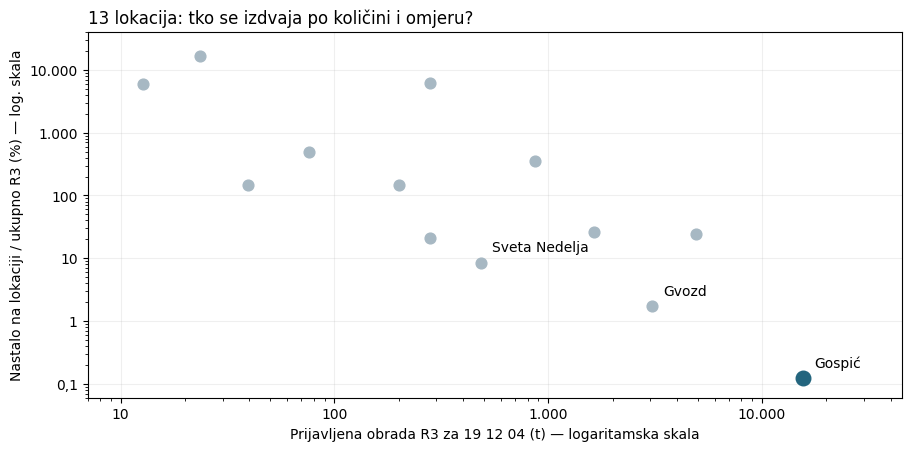

In [4]:
fig, os = plt.subplots(figsize=(9, 4.4), layout="constrained")
os.scatter(usporedba["plastika_t"], usporedba["omjer_pct"], color="#a7b8c3", s=60)
os.scatter(najmanji["plastika_t"], najmanji["omjer_pct"], color="#23657e", s=110)

for _, red in usporedba.head(3).iterrows():
    os.annotate(str(red["mjesto"]), (red["plastika_t"], red["omjer_pct"]),
                xytext=(8, 8), textcoords="offset points", fontsize=10)

os.set_xscale("log")
os.set_yscale("log")
os.set_xlim(7, 45000)
os.set_ylim(0.06, 40000)
os.set_xticks([10, 100, 1000, 10000], labels=["10", "100", "1.000", "10.000"])
os.set_yticks([0.1, 1, 10, 100, 1000, 10000], labels=["0,1", "1", "10", "100", "1.000", "10.000"])
os.set_xlabel("Prijavljena obrada R3 za 19 12 04 (t) — logaritamska skala")
os.set_ylabel("Nastalo na lokaciji / ukupno R3 (%) — log. skala")
os.set_title("13 lokacija: tko se izdvaja po količini i omjeru?", loc="left")
os.grid(alpha=0.2)
os.set_axisbelow(True)
plt.show()